<a href="https://colab.research.google.com/github/LuckySevenn/DAFT-BrainLat-AD-Classification/blob/main/notebooks/rf_xgboost_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forest y XGBoost (CN vs AD) — solo datos tabulares

Mismo protocolo de datos que `run_ftt.py`: mismas columnas, mismos sujetos y particiones (columna `split`),
mismo umbral (0.5), misma semilla y selección del mejor modelo por **balanced accuracy en validación**,
evaluándolo después en validación y test.

Ejecuta las celdas en orden. En la **Parte 3** se abre un botón para seleccionar `master.csv` desde tu PC.

## Parte 1 — Importaciones

In [ ]:
import io
import json
import time
import shutil
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)
from xgboost import XGBClassifier
from google.colab import files

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

scikit-learn 1.6.1 | xgboost 3.4.1


## Parte 2 — Configuración
Mismos nombres de columnas que `run_ftt.py`. Aquí también se definen las grillas de hiperparámetros de cada método.

In [ ]:
EXPECTED_NAME = "master.csv"   # nombre esperado del archivo (el mismo de run_ftt.py)

ID_COL = "MRI_ID"
LABEL_COL = "DX"
SPLIT_COL = "split"
POSITIVE, NEGATIVE = "Dementia", "CN"   # en DX, AD está codificado como "Dementia"
CLASS_NAMES = ["CN", "AD"]              # 0 = CN, 1 = AD

# Columnas que NO son variables de entrada (identificadores, etiquetas, partición, origen, MoCA).
EXCLUDE_COLS = [ID_COL, "country", "dx_brainlat", LABEL_COL, SPLIT_COL, "moca_total"]
CAT_FEATURES = ["sex"]

SEED = 20210129    # misma semilla que train.py de DAFT
THRESHOLD = 0.5    # mismo umbral
DPI = 150
OUT_DIR = Path("resultados_arboles")

# Misma estructura que DAFT / FT-Transformer: 5 valores x 3 valores = 15 combinaciones por método.
# Los árboles NO tienen batch size ni épocas: entrenan con todo train de una vez, así que hay una sola tabla por método.

# --- Random Forest: 5 profundidades máximas x 3 tamaños mínimos de hoja (ambos controlan la complejidad)
RF_GRID = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_leaf": [1, 3, 5],
}
RF_FIXED = {"n_estimators": 500, "max_features": "sqrt", "class_weight": None}

# --- XGBoost: 5 learning rates x 3 valores de reg_lambda (regularización L2, el análogo al weight decay)
XGB_GRID = {
    "learning_rate": [0.005, 0.01, 0.05, 0.1, 0.3],
    "reg_lambda": [0, 1, 10],
}
XGB_FIXED = {"n_estimators": 300, "max_depth": 3, "subsample": 1.0, "colsample_bytree": 1.0}

# Sin pesos por clase (class_weight=None, sin scale_pos_weight), igual que FT-Transformer y DAFT,
# que usan BCEWithLogits sin ponderar.

## Parte 3 — Seleccionar el CSV desde tu PC

In [ ]:
uploaded = files.upload()   # abre el selector de archivos
if not uploaded:
    raise ValueError("No se seleccionó ningún archivo.")

fname = next(iter(uploaded))
if fname != EXPECTED_NAME:
    print("[AVISO] El archivo se llama '{}', se esperaba '{}'. Se usará de todas formas.".format(fname, EXPECTED_NAME))

raw_df = pd.read_csv(io.BytesIO(uploaded[fname]))
print("Cargado '{}': {} filas x {} columnas".format(fname, *raw_df.shape))

missing = [c for c in [ID_COL, LABEL_COL, SPLIT_COL] + CAT_FEATURES if c not in raw_df.columns]
if missing:
    raise ValueError("Faltan columnas en el CSV: {}".format(missing))

Saving master_brianlat.csv to master_brianlat.csv
[AVISO] El archivo se llama 'master_brianlat.csv', se esperaba 'master.csv'. Se usará de todas formas.
Cargado 'master_brianlat.csv': 343 filas x 24 columnas


## Parte 4 — Preparación de los datos
Igual que `run_ftt.py`: se filtra CN/AD, se usan las particiones de la columna `split`, los faltantes se imputan
con la mediana de **train** y `sex` se codifica con las categorías vistas en train.
No se aplica z-score porque los árboles no dependen de la escala de las variables.

In [ ]:
def _norm_split(s):
    s = str(s).strip().lower()
    return {"val": "valid", "validation": "valid", "validacion": "valid", "validación": "valid"}.get(s, s)


def prepare_data(df):
    df = df.copy()
    df[SPLIT_COL] = df[SPLIT_COL].map(_norm_split)
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    df = df[df[LABEL_COL].isin([POSITIVE, NEGATIVE])].reset_index(drop=True)

    cont = [c for c in df.columns if c not in EXCLUDE_COLS + CAT_FEATURES]
    for c in cont:
        converted = pd.to_numeric(df[c], errors="coerce")
        bad = df[c].notna() & converted.isna()
        if bad.any():
            print("  [AVISO] '{}': {} valores no numéricos tratados como faltantes. Ejemplos: {}".format(
                c, int(bad.sum()), sorted(df.loc[bad, c].astype(str).unique())[:5]))
        df[c] = converted

    train = df[df[SPLIT_COL] == "train"]
    if train.empty:
        raise ValueError("No hay sujetos de train con {} en {{{}, {}}}.".format(LABEL_COL, POSITIVE, NEGATIVE))

    empty_cols = [c for c in cont if train[c].isna().all()]
    if empty_cols:
        print("  [AVISO] Columnas sin ningún valor en train (se descartan): {}".format(empty_cols))
        cont = [c for c in cont if c not in empty_cols]

    # Continuas: imputación con la mediana de train.
    medians = train[cont].median()
    X = df[cont].astype("float32").fillna(medians)

    # Categóricas: códigos 0..k-1 aprendidos en train; faltantes -> moda de train.
    for c in CAT_FEATURES:
        col = df[c].fillna(train[c].mode().iloc[0])
        cats = sorted(train[c].dropna().unique().tolist())
        unseen = set(col.unique()) - set(cats)
        if unseen:
            raise ValueError("La variable '{}' tiene valores que no aparecen en train: {}".format(c, unseen))
        X[c] = col.map({v: i for i, v in enumerate(cats)}).astype("int64")

    y = (df[LABEL_COL] == POSITIVE).astype(int).values

    data = {}
    for split in ["train", "valid", "test"]:
        idx = np.where(df[SPLIT_COL].values == split)[0]
        n_ad = int(y[idx].sum())
        print("  {:<5}: {:>3} sujetos  (AD={}, CN={})".format(split, len(idx), n_ad, len(idx) - n_ad))
        if n_ad == 0 or n_ad == len(idx):
            raise ValueError("La partición '{}' no tiene las dos clases.".format(split))
        data[split] = {"ids": df[ID_COL].values[idx],
                       "X": X.iloc[idx].reset_index(drop=True),
                       "y": y[idx]}

    features = cont + CAT_FEATURES
    print("  Variables continuas ({}): {}".format(len(cont), ", ".join(cont)))
    print("  Variables categóricas: {}".format(", ".join(CAT_FEATURES) or "ninguna"))
    return data, features


data, FEATURES = prepare_data(raw_df)

  train: 240 sujetos  (AD=144, CN=96)
  valid:  52 sujetos  (AD=31, CN=21)
  test :  51 sujetos  (AD=31, CN=20)
  Variables continuas (18): age, years_education, hippocampus_L, hippocampus_R, lat_ventricle_L, lat_ventricle_R, entorhinal_thk_L, entorhinal_thk_R, inftemporal_thk_L, inftemporal_thk_R, parahippo_thk_L, parahippo_thk_R, ca1_L, ca1_R, subiculum_L, subiculum_R, basolat_amyg_L, basolat_amyg_R
  Variables categóricas: sex


## Parte 5 — Métricas y gráficas (mismo formato que `run_ftt.py`)

In [ ]:
METRIC_KEYS = ["accuracy", "balanced_accuracy", "sensitivity_AD", "specificity_CN", "f1_AD", "f1_macro", "f1_weighted", "auc"]
COUNT_KEYS = ["TP", "FN", "TN", "FP"]

# Tabla resumen: encabezado de dos niveles (Valid / Test), mismo formato que la tabla del FT-Transformer.
# F1 general: "F1 macro" = promedio simple del F1 de CN y de AD (las dos clases pesan igual);
#             "F1 ponderado" = promedio del F1 de cada clase ponderado por su número de sujetos.
TABLE_METRICS = [("balanced_accuracy", "Bal. Acc.", "pct"), ("sensitivity_AD", "Sens. AD", "pct"),
                 ("specificity_CN", "Esp. CN", "pct"), ("auc", "AUC", "pct"),
                 ("f1_macro", "F1 macro", "pct"), ("f1_weighted", "F1 ponderado", "pct"),
                 ("TP", "TP", "int"), ("FN", "FN", "int"), ("TN", "TN", "int"), ("FP", "FP", "int")]
TABLE_SPLITS = [("valid", "Valid", "val"), ("test", "Test", "test")]

def _fmt(v, kind):
    if pd.isna(v):
        return ""
    return "{:.1f}%".format(100 * v) if kind == "pct" else int(v)

def build_table(results, param_cols):
    table = results[param_cols].copy()
    table.columns = pd.MultiIndex.from_tuples([("Parámetros", c) for c in param_cols])
    for split, group, tag in TABLE_SPLITS:
        for key, label, kind in TABLE_METRICS:
            col = "{}_{}".format(split, key)
            table[(group, "{} ({})".format(label, tag))] = results[col].map(lambda v, k=kind: _fmt(v, k))
    return table


def summary_metrics(y_true, y_pred, prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "n": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "sensitivity_AD": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity_CN": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1_AD": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan,
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
    }


def evaluate(model, d):
    prob = model.predict_proba(d["X"])[:, 1]
    pred = (prob >= THRESHOLD).astype(int)
    return prob, pred, summary_metrics(d["y"], pred, prob)


def plot_confusion(y_true, y_pred, path, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, "{}\n({:.1f}%)".format(cm[i, j], pct[i, j]), ha="center", va="center",
                    color="white" if pct[i, j] > 50 else "black", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Diagnóstico real")
    ax.set_title(title, fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=DPI); plt.show(); plt.close(fig)


def plot_roc(y_true, prob, path, title):
    fig, ax = plt.subplots(figsize=(5, 4.6))
    fpr, tpr, _ = roc_curve(y_true, prob)
    ax.plot(fpr, tpr, linewidth=2, label="AUC = {:.3f}".format(roc_auc_score(y_true, prob)))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
    ax.set_xlabel("1 - Especificidad (tasa de falsos positivos)")
    ax.set_ylabel("Sensibilidad (tasa de verdaderos positivos)")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(loc="lower right")
    fig.tight_layout(); fig.savefig(path, dpi=DPI); plt.show(); plt.close(fig)


def plot_importance(model, features, path, title, top=20):
    imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
    imp.rename("importance").to_csv(path.with_suffix(".csv"), header=True)
    top_imp = imp.head(top)[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(top_imp) + 1.5))
    ax.barh(top_imp.index, top_imp.values)
    ax.set_xlabel("Importancia")
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3, axis="x")
    fig.tight_layout(); fig.savefig(path, dpi=DPI); plt.show(); plt.close(fig)

## Parte 6 — Función de la grilla
Entrena cada combinación con los datos de **train**, evalúa en validación y test, y guarda
`<metodo>_grid_results.csv` (todas las métricas) y `<metodo>_tabla.csv` (mismo formato que la tabla del FT-Transformer). El mejor modelo (mayor balanced accuracy en validación; si hay empate, mayor AUC
en validación) se guarda con sus gráficas y predicciones en `resultados_arboles/<metodo>/best_model/`.

In [ ]:
def expand_grid(grid):
    keys = list(grid)
    return [dict(zip(keys, values)) for values in itertools.product(*grid.values())]


def run_grid(arch, make_model, grid, fixed):
    out = OUT_DIR / arch
    best_dir = out / "best_model"
    best_dir.mkdir(parents=True, exist_ok=True)

    combos = expand_grid(grid)
    rows, best = [], {"score": (-1.0, -1.0), "model": None, "params": None, "row": None}
    t0 = time.time()
    print("{}: {} combinaciones".format(arch, len(combos)))

    for i, params in enumerate(combos, 1):
        row = {"arch": arch, **{k: ("None" if v is None else v) for k, v in params.items()}}
        try:
            model = make_model({**fixed, **params})
            model.fit(data["train"]["X"], data["train"]["y"])
            for split in ["train", "valid", "test"]:
                _, _, m = evaluate(model, data[split])
                row.update({"{}_{}".format(split, k): m[k] for k in METRIC_KEYS + COUNT_KEYS})
            score = (row["valid_balanced_accuracy"], row["valid_auc"])
            if score > best["score"]:
                best = {"score": score, "model": model, "params": params, "row": row}
            print("  [{:>3}/{}] val bacc={:.3f} auc={:.3f} | test bacc={:.3f} | {}".format(
                i, len(combos), row["valid_balanced_accuracy"], row["valid_auc"],
                row["test_balanced_accuracy"], params))
        except Exception as e:   # una combinación fallida no detiene la grilla
            row["error"] = str(e)
            print("  [{:>3}/{}] ERROR: {}".format(i, len(combos), e))
        rows.append(row)

    results = pd.DataFrame(rows)   # en el orden de la grilla, como las tablas de DAFT / FT-Transformer
    results_path = OUT_DIR / "{}_grid_results.csv".format(arch)
    results.to_csv(results_path, index=False)

    # Tabla con el mismo formato que la del FT-Transformer (porcentajes)
    table = build_table(results, list(grid))
    table.to_csv(OUT_DIR / "{}_tabla.csv".format(arch), index=False)
    print("\nTiempo: {:.1f} min | resultados en {}".format((time.time() - t0) / 60, results_path))

    # --- Mejor modelo: gráficas, predicciones y métricas
    model, params = best["model"], best["params"]
    title = "{} | {}".format(arch, ", ".join("{}={}".format(k, v) for k, v in params.items()))
    print("\nMejor combinación (por validación): {}".format(params))
    with open(best_dir / "best_params.json", "w") as f:
        json.dump({k: ("None" if v is None else v) for k, v in {**fixed, **params}.items()}, f, indent=2)

    metric_rows = []
    for split in ["valid", "test"]:
        name = "Validación" if split == "valid" else "Test"
        prob, pred, m = evaluate(model, data[split])
        y_true = data[split]["y"]
        plot_confusion(y_true, pred, best_dir / "confusion_matrix_{}.png".format(split),
                       "Matriz de confusión — {}\n{}".format(name, title))
        plot_roc(y_true, prob, best_dir / "roc_{}.png".format(split), "Curva ROC — {}\n{}".format(name, title))
        pd.DataFrame({ID_COL: data[split]["ids"], "y_true": y_true, "y_pred": pred, "prob_AD": prob}).to_csv(
            best_dir / "predictions_{}.csv".format(split), index=False)
        m["split"] = split
        metric_rows.append(m)
    plot_importance(model, FEATURES, best_dir / "feature_importance.png", "Importancia de variables\n" + title)

    metrics = pd.DataFrame(metric_rows).set_index("split")
    metrics.to_csv(best_dir / "metrics.csv")
    display(metrics[["n", "accuracy", "balanced_accuracy", "sensitivity_AD", "specificity_CN", "f1_AD", "f1_macro", "f1_weighted", "auc"]].round(3))

    print("\nTabla completa ({}, parámetros fijos: {}):".format(arch, fixed))
    display(table)
    return results, best["row"]

## Parte 7 — Grilla Random Forest

random_forest: 15 combinaciones
  [  1/15] val bacc=0.801 auc=0.928 | test bacc=0.769 | {'max_depth': 3, 'min_samples_leaf': 1}
  [  2/15] val bacc=0.801 auc=0.923 | test bacc=0.769 | {'max_depth': 3, 'min_samples_leaf': 3}
  [  3/15] val bacc=0.801 auc=0.922 | test bacc=0.769 | {'max_depth': 3, 'min_samples_leaf': 5}
  [  4/15] val bacc=0.801 auc=0.920 | test bacc=0.769 | {'max_depth': 5, 'min_samples_leaf': 1}
  [  5/15] val bacc=0.801 auc=0.911 | test bacc=0.769 | {'max_depth': 5, 'min_samples_leaf': 3}
  [  6/15] val bacc=0.801 auc=0.908 | test bacc=0.769 | {'max_depth': 5, 'min_samples_leaf': 5}
  [  7/15] val bacc=0.777 auc=0.908 | test bacc=0.769 | {'max_depth': 7, 'min_samples_leaf': 1}
  [  8/15] val bacc=0.777 auc=0.908 | test bacc=0.769 | {'max_depth': 7, 'min_samples_leaf': 3}
  [  9/15] val bacc=0.777 auc=0.908 | test bacc=0.769 | {'max_depth': 7, 'min_samples_leaf': 5}
  [ 10/15] val bacc=0.777 auc=0.903 | test bacc=0.769 | {'max_depth': 10, 'min_samples_leaf': 1}
  [ 11/

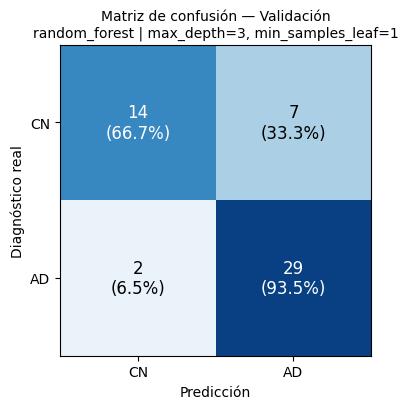

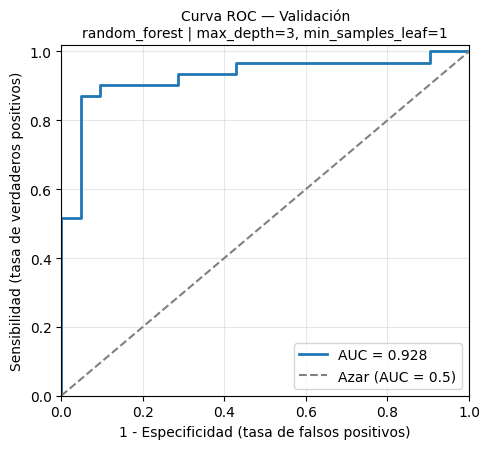

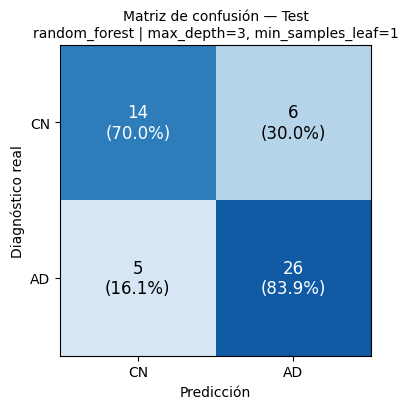

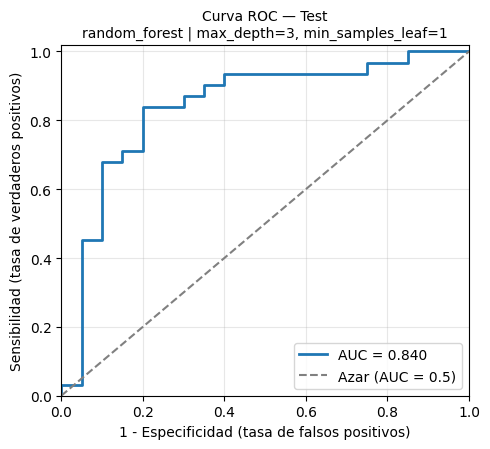

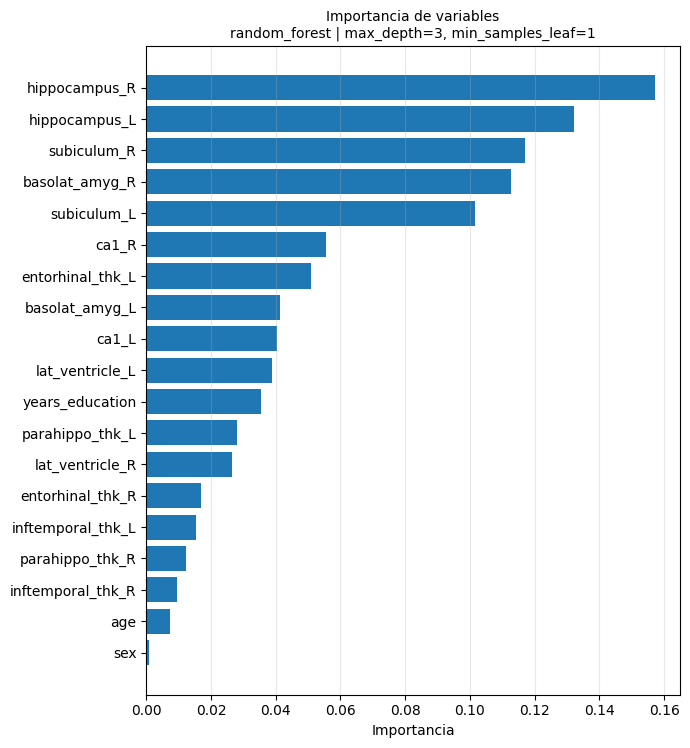

,n,accuracy,balanced_accuracy,sensitivity_AD,specificity_CN,f1_AD,f1_macro,f1_weighted,auc
split,,,,,,,,,
valid,52,0.827,0.801,0.935,0.667,0.866,0.811,0.822,0.928
test,51,0.784,0.769,0.839,0.700,0.825,0.772,0.783,0.840



Tabla completa (random_forest, parámetros fijos: {'n_estimators': 500, 'max_features': 'sqrt', 'class_weight': None}):


Parámetros                            Valid                               \
    max_depth min_samples_leaf Bal. Acc. (val) Sens. AD (val) Esp. CN (val)   
0           3                1           80.1%          93.5%         66.7%   
1           3                3           80.1%          93.5%         66.7%   
2           3                5           80.1%          93.5%         66.7%   
3           5                1           80.1%          93.5%         66.7%   
4           5                3           80.1%          93.5%         66.7%   
5           5                5           80.1%          93.5%         66.7%   
6           7                1           77.7%          93.5%         61.9%   
7           7                3           77.7%          93.5%         61.9%   
8           7                5           77.7%          93.5%         61.9%   
9          10                1           77.7%          93.5%         61.9%   
10         10                3           77.7%          93.5%         61.9%   
11         10                5           77.7%          93.5%         61.9%   
12       None                1           77.7%          93.5%         61.9%   
13       None                3           77.7%          93.5%         61.9%   
14       None                5           77.7%          93.5%         61.9%   

                                                                  ...  \
   AUC (val) F1 macro (val) F1 ponderado (val) TP (val) FN (val)  ...   
0      92.8%          81.1%              82.2%       29        2  ...   
1      92.3%          81.1%              82.2%       29        2  ...   
2      92.2%          81.1%              82.2%       29        2  ...   
3      92.0%          81.1%              82.2%       29        2  ...   
4      91.1%          81.1%              82.2%       29        2  ...   
5      90.8%          81.1%              82.2%       29        2  ...   
6      90.8%          78.8%              80.0%       29        2  ...   
7      90.8%          78.8%              80.0%       29        2  ...   
8      90.8%          78.8%              80.0%       29        2  ...   
9      90.3%          78.8%              80.0%       29        2  ...   
10     90.5%          78.8%              80.0%       29        2  ...   
11     90.8%          78.8%              80.0%       29        2  ...   
12     90.4%          78.8%              80.0%       29        2  ...   
13     90.5%          78.8%              80.0%       29        2  ...   
14     90.8%          78.8%              80.0%       29        2  ...   

               Test                                                            \
   Bal. Acc. (test) Sens. AD (test) Esp. CN (test) AUC (test) F1 macro (test)   
0             76.9%           83.9%          70.0%      84.0%           77.2%   
1             76.9%           83.9%          70.0%      84.2%           77.2%   
2             76.9%           83.9%          70.0%      84.5%           77.2%   
3             76.9%           83.9%          70.0%      83.5%           77.2%   
4             76.9%           83.9%          70.0%      83.4%           77.2%   
5             76.9%           83.9%          70.0%      83.4%           77.2%   
6             76.9%           83.9%          70.0%      83.1%           77.2%   
7             76.9%           83.9%          70.0%      82.6%           77.2%   
8             76.9%           83.9%          70.0%      82.9%           77.2%   
9             76.9%           83.9%          70.0%      84.4%           77.2%   
10            76.9%           83.9%          70.0%      82.7%           77.2%   
11            76.9%           83.9%          70.0%      82.7%           77.2%   
12            76.9%           83.9%          70.0%      84.2%           77.2%   
13            76.9%           83.9%          70.0%      82.7%           77.2%   
14            76.9%           83.9%          70.0%      82.7%           77.2%   

                                       

In [ ]:
def make_rf(params):
    return RandomForestClassifier(**params, random_state=SEED, n_jobs=-1)


rf_results, rf_best = run_grid("random_forest", make_rf, RF_GRID, RF_FIXED)

## Parte 8 — Grilla XGBoost

xgboost: 15 combinaciones
  [  1/15] val bacc=0.777 auc=0.907 | test bacc=0.753 | {'learning_rate': 0.005, 'reg_lambda': 0}
  [  2/15] val bacc=0.777 auc=0.915 | test bacc=0.737 | {'learning_rate': 0.005, 'reg_lambda': 1}
  [  3/15] val bacc=0.777 auc=0.922 | test bacc=0.728 | {'learning_rate': 0.005, 'reg_lambda': 10}
  [  4/15] val bacc=0.777 auc=0.877 | test bacc=0.753 | {'learning_rate': 0.01, 'reg_lambda': 0}
  [  5/15] val bacc=0.777 auc=0.880 | test bacc=0.737 | {'learning_rate': 0.01, 'reg_lambda': 1}
  [  6/15] val bacc=0.801 auc=0.912 | test bacc=0.737 | {'learning_rate': 0.01, 'reg_lambda': 10}
  [  7/15] val bacc=0.785 auc=0.842 | test bacc=0.778 | {'learning_rate': 0.05, 'reg_lambda': 0}
  [  8/15] val bacc=0.785 auc=0.833 | test bacc=0.762 | {'learning_rate': 0.05, 'reg_lambda': 1}
  [  9/15] val bacc=0.777 auc=0.862 | test bacc=0.753 | {'learning_rate': 0.05, 'reg_lambda': 10}
  [ 10/15] val bacc=0.785 auc=0.845 | test bacc=0.746 | {'learning_rate': 0.1, 'reg_lambda': 0}

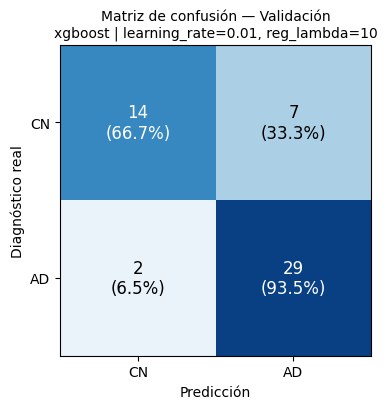

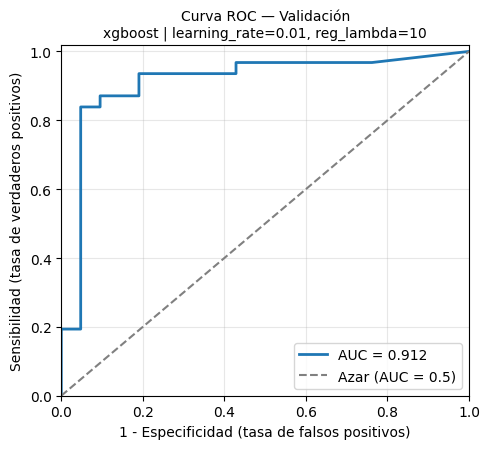

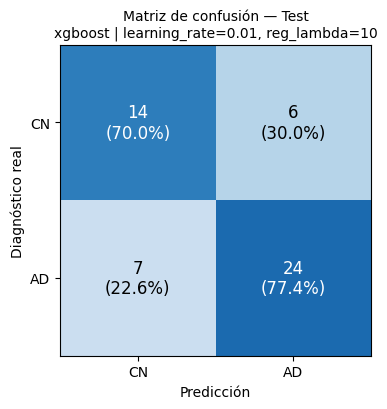

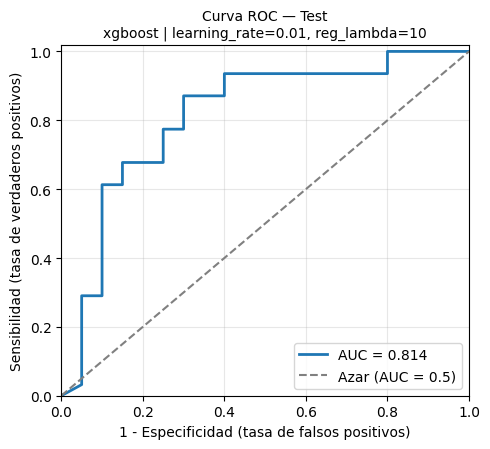

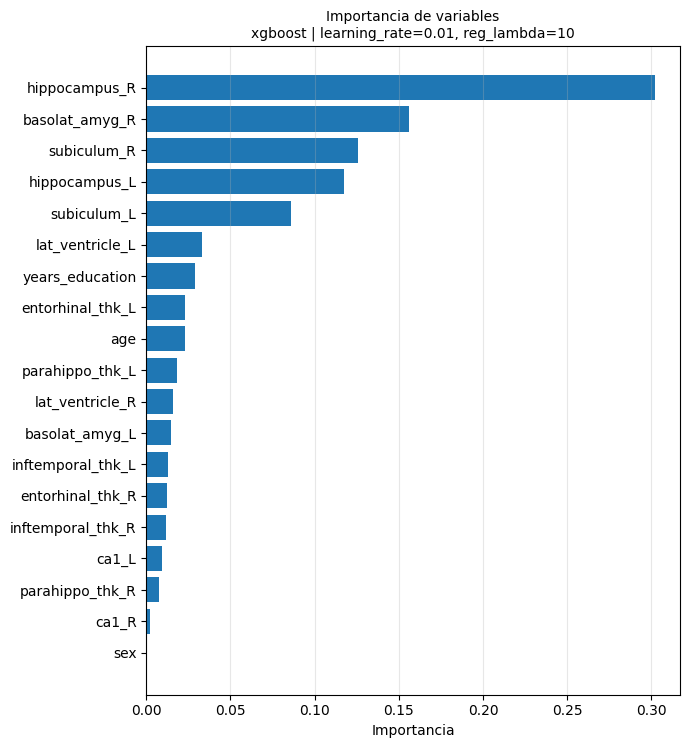

,n,accuracy,balanced_accuracy,sensitivity_AD,specificity_CN,f1_AD,f1_macro,f1_weighted,auc
split,,,,,,,,,
valid,52,0.827,0.801,0.935,0.667,0.866,0.811,0.822,0.912
test,51,0.745,0.737,0.774,0.700,0.787,0.735,0.746,0.814



Tabla completa (xgboost, parámetros fijos: {'n_estimators': 300, 'max_depth': 3, 'subsample': 1.0, 'colsample_bytree': 1.0}):


Parámetros                      Valid                               \
   learning_rate reg_lambda Bal. Acc. (val) Sens. AD (val) Esp. CN (val)   
0          0.005          0           77.7%          93.5%         61.9%   
1          0.005          1           77.7%          93.5%         61.9%   
2          0.005         10           77.7%          93.5%         61.9%   
3          0.010          0           77.7%          93.5%         61.9%   
4          0.010          1           77.7%          93.5%         61.9%   
5          0.010         10           80.1%          93.5%         66.7%   
6          0.050          0           78.5%          90.3%         66.7%   
7          0.050          1           78.5%          90.3%         66.7%   
8          0.050         10           77.7%          93.5%         61.9%   
9          0.100          0           78.5%          90.3%         66.7%   
10         0.100          1           78.5%          90.3%         66.7%   
11         0.100         10           80.1%          93.5%         66.7%   
12         0.300          0           78.5%          90.3%         66.7%   
13         0.300          1           76.1%          90.3%         61.9%   
14         0.300         10           80.1%          93.5%         66.7%   

                                                                  ...  \
   AUC (val) F1 macro (val) F1 ponderado (val) TP (val) FN (val)  ...   
0      90.7%          78.8%              80.0%       29        2  ...   
1      91.5%          78.8%              80.0%       29        2  ...   
2      92.2%          78.8%              80.0%       29        2  ...   
3      87.7%          78.8%              80.0%       29        2  ...   
4      88.0%          78.8%              80.0%       29        2  ...   
5      91.2%          81.1%              82.2%       29        2  ...   
6      84.2%          79.3%              80.3%       28        3  ...   
7      83.3%          79.3%              80.3%       28        3  ...   
8      86.2%          78.8%              80.0%       29        2  ...   
9      84.5%          79.3%              80.3%       28        3  ...   
10     82.8%          79.3%              80.3%       28        3  ...   
11     83.9%          81.1%              82.2%       29        2  ...   
12     83.9%          79.3%              80.3%       28        3  ...   
13     82.8%          76.9%              78.2%       28        3  ...   
14     83.9%          81.1%              82.2%       29        2  ...   

               Test                                                            \
   Bal. Acc. (test) Sens. AD (test) Esp. CN (test) AUC (test) F1 macro (test)   
0             75.3%           80.6%          70.0%      81.0%           75.3%   
1             73.7%           77.4%          70.0%      81.4%           73.5%   
2             72.8%           80.6%          65.0%      80.2%           73.0%   
3             75.3%           80.6%          70.0%      82.3%           75.3%   
4             73.7%           77.4%          70.0%      82.7%           73.5%   
5             73.7%           77.4%          70.0%      81.4%           73.5%   
6             77.8%           80.6%          75.0%      82.7%           77.6%   
7             76.2%           77.4%          75.0%      82.6%           75.7%   
8             75.3%           80.6%          70.0%      82.4%           75.3%   
9             74.6%           74.2%          75.0%      81.5%           73.9%   
10            76.2%           77.4%          75.0%      82.3%           75.7%   
11            73.7%           77.4%          70.0%      81.6%           73.5%   
12            77.8%           80.6%          75.0%      82.4%           77.6%   
13            75.3%           80.6%          70.0%      81.3%           75.3%   
14            73.7%           77.4%          70.0%      80.8%           73.5%   

                                                                
   F1 ponderado (test) TP (t

In [ ]:
def make_xgb(params):
    return XGBClassifier(**params, objective="binary:logistic", eval_metric="logloss",
                         tree_method="hist", random_state=SEED, n_jobs=-1)


xgb_results, xgb_best = run_grid("xgboost", make_xgb, XGB_GRID, XGB_FIXED)

## Parte 9 — Comparación y descarga de resultados

In [ ]:
cols = ["arch"] + ["{}_{}".format(s, k) for s in ["valid", "test"] for k in METRIC_KEYS]
comparison = pd.DataFrame([rf_best, xgb_best])[cols]
comparison.to_csv(OUT_DIR / "comparacion_mejores.csv", index=False)
display(comparison.round(3))

#shutil.make_archive("resultados_arboles", "zip", OUT_DIR)
#files.download("resultados_arboles.zip")

NameError: name 'xgb_best' is not defined

## Parte 10 — Test ADNI (test externo)

Entrena **Random Forest** y **XGBoost** solo con la configuración elegida (sin grilla):

| Modelo | Configuración |
|---|---|
| XGBoost | learning_rate = 0.01, reg_lambda = 10 |
| Random Forest | max_depth = 3, min_samples_leaf = 1 |

El resto de parámetros son los fijos de la Parte 2 (`XGB_FIXED`, `RF_FIXED`). El CSV de ADNI solo trae sujetos de test, así que se usa como **test externo**: los modelos se entrenan con la partición `train` de BrainLat y se evalúan sobre todos los sujetos de ADNI. Los faltantes de ADNI se imputan con la mediana de train de BrainLat y `sex` se codifica con sus categorías (mismo umbral y semilla). Al ejecutar la celda se abre el selector de archivos para elegir el CSV de ADNI. La tabla se guarda en `resultados_arboles/test_adni/tabla_test_adni.csv`.

In [ ]:
# --- Configuraciones fijas para el Test ADNI (sin grilla)
# El CSV de ADNI solo trae sujetos de test (split = "test"), así que se usa como TEST EXTERNO:
# los modelos se entrenan con train de BrainLat (Partes 3-4) y se evalúan sobre todo ADNI.
ADNI_CONFIGS = [
    ("XGBoost", make_xgb, {**XGB_FIXED, "learning_rate": 0.01, "reg_lambda": 10}),
    ("Random Forest", make_rf, {**RF_FIXED, "max_depth": 3, "min_samples_leaf": 1}),
]
ADNI_OUT = OUT_DIR / "test_adni"
ADNI_OUT.mkdir(parents=True, exist_ok=True)

if "data" not in globals() or "FEATURES" not in globals():
    raise RuntimeError("Primero ejecuta las Partes 1 a 5 y 7-8 (carga y preparación de BrainLat).")

# --- 1) Seleccionar el CSV de ADNI desde tu PC
print("Selecciona el CSV de ADNI:")
uploaded_adni = files.upload()
if not uploaded_adni:
    raise ValueError("No se seleccionó ningún archivo.")
adni_fname = next(iter(uploaded_adni))
adni_raw = pd.read_csv(io.BytesIO(uploaded_adni[adni_fname]))
print("Cargado '{}': {} filas x {} columnas".format(adni_fname, *adni_raw.shape))

# --- 2) Preparar ADNI con las estadísticas de train de BrainLat (sin fuga de información)
def _brainlat_train_stats():
    df = raw_df.copy()
    df[SPLIT_COL] = df[SPLIT_COL].map(_norm_split)
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    tr = df[(df[SPLIT_COL] == "train") & df[LABEL_COL].isin([POSITIVE, NEGATIVE])]
    cont = [c for c in FEATURES if c not in CAT_FEATURES]
    medians = tr[cont].apply(pd.to_numeric, errors="coerce").median()
    cats = {c: sorted(tr[c].dropna().unique().tolist()) for c in CAT_FEATURES}
    modes = {c: tr[c].mode().iloc[0] for c in CAT_FEATURES}
    return cont, medians, cats, modes

def prepare_adni(df):
    cont, medians, cats, modes = _brainlat_train_stats()
    missing = [c for c in [ID_COL, LABEL_COL] + FEATURES if c not in df.columns]
    if missing:
        raise ValueError("Faltan columnas en el CSV de ADNI (deben ser las mismas de BrainLat): {}".format(missing))
    df = df.copy()
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    df = df[df[LABEL_COL].isin([POSITIVE, NEGATIVE])].reset_index(drop=True)

    X = df[cont].apply(pd.to_numeric, errors="coerce").astype("float32").fillna(medians)
    for c in CAT_FEATURES:
        col = df[c].fillna(modes[c])
        unseen = set(col.unique()) - set(cats[c])
        if unseen:
            raise ValueError("La variable '{}' en ADNI tiene valores que no aparecen en train de BrainLat: {}".format(c, unseen))
        X[c] = col.map({v: i for i, v in enumerate(cats[c])}).astype("int64")
    X = X[FEATURES]  # mismo orden de columnas que en el entrenamiento

    y = (df[LABEL_COL] == POSITIVE).astype(int).values
    n_ad = int(y.sum())
    print("  ADNI (test externo): {} sujetos (AD={}, CN={})".format(len(y), n_ad, len(y) - n_ad))
    if n_ad == 0 or n_ad == len(y):
        raise ValueError("El CSV de ADNI no tiene las dos clases.")
    return {"ids": df[ID_COL].values, "X": X, "y": y}

adni_test = prepare_adni(adni_raw)
print("  Entrenamiento: train de BrainLat ({} sujetos)".format(len(data["train"]["y"])))

# --- 3) Entrenar cada modelo con su configuración en BrainLat y evaluar en ADNI
pct = lambda v: "{:.1f}%".format(100 * v) if pd.notna(v) else ""
adni_rows = []
for name, make_model, params in ADNI_CONFIGS:
    model = make_model(params)
    model.fit(data["train"]["X"][FEATURES], data["train"]["y"])
    prob, pred, m = evaluate(model, adni_test)
    pd.DataFrame({ID_COL: adni_test["ids"], "y_true": adni_test["y"],
                  "y_pred": pred, "prob_AD": prob}).to_csv(
        ADNI_OUT / "predictions_adni_{}.csv".format(name.lower().replace(" ", "_")), index=False)
    adni_rows.append({
        "Modelo": name,
        "Bal. Acc. (test)": pct(m["balanced_accuracy"]),
        "Sens. AD (test)": pct(m["sensitivity_AD"]),
        "Esp. CN (test)": pct(m["specificity_CN"]),
        "AUC (test)": pct(m["auc"]),
        "F1 macro (test)": pct(m["f1_macro"]),
        "F1 ponderado (test)": pct(m["f1_weighted"]),
        "TP (test)": int(m["TP"]),
        "FN (test)": int(m["FN"]),
        "TN (test)": int(m["TN"]),
        "FP (test)": int(m["FP"]),
        "Acc. (test)": pct(m["accuracy"]),
        "N muestras": int(m["n"]),
    })

adni_table = pd.DataFrame(adni_rows).set_index("Modelo")
adni_table.to_csv(ADNI_OUT / "tabla_test_adni.csv")
print("\nTest ADNI — XGBoost (learning_rate=0.01, reg_lambda=10) | Random Forest (max_depth=3, min_samples_leaf=1)")
display(adni_table)


Selecciona el CSV de ADNI:


Saving master.csv to master.csv
Cargado 'master.csv': 100 filas x 24 columnas
  ADNI (test externo): 100 sujetos (AD=50, CN=50)
  Entrenamiento: train de BrainLat (240 sujetos)

Test ADNI — XGBoost (learning_rate=0.01, reg_lambda=10) | Random Forest (max_depth=3, min_samples_leaf=1)


,Bal. Acc. (test),Sens. AD (test),Esp. CN (test),AUC (test),F1 macro (test),F1 ponderado (test),TP (test),FN (test),TN (test),FP (test),Acc. (test),N muestras
Modelo,,,,,,,,,,,,
XGBoost,84.0%,96.0%,72.0%,95.1%,83.8%,83.8%,48,2,36,14,84.0%,100
Random Forest,86.0%,98.0%,74.0%,96.2%,85.8%,85.8%,49,1,37,13,86.0%,100
